# Chapitre 4 - Exercices 4.1 à 4.5

- **4.1** : problème aux valeurs propres généralisé ;
- **4.2** : LDA et moindres carrés à deux classes ;
- **4.3** : LDA sur les réponses ajustées de la régression sur indicatrices ;
- **4.4** : Newton-Raphson pour la logistique multinomiale ;
- **4.5** : régression logistique sur des données séparables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

## Exercice 4.1 : Problème aux valeurs propres généralisé

**Énoncé.** Montrer comment résoudre le problème
$\max_a a^T\mathbf{B}a$ sous la contrainte $a^T\mathbf{W}a = 1$ en le ramenant à un
problème aux valeurs propres standard. (Ici $\mathbf{B}$ est symétrique semi-définie
positive et $\mathbf{W}$ symétrique définie positive, comme les covariances inter- et
intra-classes de la LDA de rang réduit.)

### Rappels

- **Théorème spectral.** Une matrice symétrique réelle $\mathbf{S}$ s'écrit
  $\mathbf{S} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ avec $\mathbf{U}$ orthogonale (colonnes
  $u_j$ orthonormées) et $\mathbf{D} = \operatorname{diag}(\lambda_1 \ge \dots \ge \lambda_p)$.
- **Racine carrée.** Si $\mathbf{W} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ est définie positive
  ($\lambda_j > 0$), on pose $\mathbf{W}^{1/2} = \mathbf{U}\mathbf{D}^{1/2}\mathbf{U}^T$ :
  elle est symétrique, inversible, d'inverse $\mathbf{W}^{-1/2} = \mathbf{U}\mathbf{D}^{-1/2}\mathbf{U}^T$,
  et $\mathbf{W}^{1/2}\mathbf{W}^{1/2} = \mathbf{W}$.

### Lemme : maximum d'une forme quadratique sur la sphère

Soit $\mathbf{S} = \mathbf{U}\mathbf{D}\mathbf{U}^T$ symétrique. Alors
$\max_{\|b\| = 1} b^T\mathbf{S}b = \lambda_1$, atteint en $b = u_1$.

*Preuve.* Écrivons $b = \sum_j c_ju_j$ dans la base orthonormée des $u_j$ ; on a
$\|b\|^2 = \sum_j c_j^2 = 1$ et, puisque $\mathbf{S}u_j = \lambda_ju_j$ et $u_j^Tu_k = \delta_{jk}$,
$$b^T\mathbf{S}b = \sum_j\lambda_jc_j^2 \le \lambda_1\sum_jc_j^2 = \lambda_1.$$
L'égalité a lieu pour $c = (1, 0, \dots, 0)$, c'est-à-dire $b = u_1$. $\square$

### Solution

On fait le **changement de variable** $b = \mathbf{W}^{1/2}a$, bijectif car
$\mathbf{W}^{1/2}$ est inversible ($a = \mathbf{W}^{-1/2}b$).

- La contrainte devient $a^T\mathbf{W}a = a^T\mathbf{W}^{1/2}\mathbf{W}^{1/2}a = b^Tb = 1$
  (on a utilisé la symétrie de $\mathbf{W}^{1/2}$).
- L'objectif devient $a^T\mathbf{B}a = b^T\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}b = b^T\mathbf{B}^*b$
  avec $\mathbf{B}^* = \mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}$, symétrique.

Le problème est donc $\max_{\|b\|=1} b^T\mathbf{B}^*b$, un problème aux valeurs propres
**standard** : par le lemme, la solution est le premier vecteur propre $v_1^*$ de
$\mathbf{B}^*$, la valeur optimale est sa plus grande valeur propre $\lambda_1$, et
$$a_1 = \mathbf{W}^{-1/2}v_1^*.$$

**Variantes équivalentes.**

1. Avec la factorisation de Cholesky $\mathbf{W} = \mathbf{L}\mathbf{L}^T$ ($\mathbf{L}$
   triangulaire inférieure), on pose $b = \mathbf{L}^Ta$ et l'on diagonalise
   $\mathbf{L}^{-1}\mathbf{B}\mathbf{L}^{-T}$ - moins coûteux qu'une racine carrée.
2. En multipliant $\mathbf{B}^*v^* = \lambda v^*$ à gauche par $\mathbf{W}^{-1/2}$ et en
   posant $a = \mathbf{W}^{-1/2}v^*$, on obtient $\mathbf{W}^{-1}\mathbf{B}a = \lambda a$ :
   $a_1$ est aussi vecteur propre de $\mathbf{W}^{-1}\mathbf{B}$, mais cette matrice n'est
   **pas symétrique**, d'où l'intérêt de la forme symétrique $\mathbf{B}^*$ pour le calcul.
3. Les directions suivantes ($a_\ell$ maximisant $a^T\mathbf{B}a$ sous $a^T\mathbf{W}a = 1$ et
   $a^T\mathbf{W}a_m = 0$ pour $m<\ell$) sont $a_\ell = \mathbf{W}^{-1/2}v_\ell^*$, car la
   $\mathbf{W}$-orthogonalité des $a$ équivaut à l'orthogonalité usuelle des $b$.

### Vérification numérique

On tire au hasard $\mathbf{B}$ (de rang 3) et $\mathbf{W}$, puis on compare les quatre
calculs : racine carrée, Cholesky, $\mathbf{W}^{-1}\mathbf{B}$ et le solveur généralisé de
scipy (`linalg.eigh(B, W)`).

In [2]:
rng = np.random.RandomState(0)
p = 5
A_ = rng.randn(p, p)
W = A_ @ A_.T + np.eye(p)
G = rng.randn(p, 3)
B = G @ G.T

dW, UW = np.linalg.eigh(W)
W_m12 = UW @ np.diag(dW ** -0.5) @ UW.T
l1, v1 = np.linalg.eigh(W_m12 @ B @ W_m12)
a_racine = W_m12 @ v1[:, -1]

Lw = np.linalg.cholesky(W)
Li = np.linalg.inv(Lw)
l2, v2 = np.linalg.eigh(Li @ B @ Li.T)
a_chol = Li.T @ v2[:, -1]

l3, v3 = np.linalg.eig(np.linalg.solve(W, B))
a_nonsym = np.real(v3[:, np.argmax(np.real(l3))])
a_nonsym /= np.sqrt(a_nonsym @ W @ a_nonsym)

l4, v4 = linalg.eigh(B, W)
a_scipy = v4[:, -1]

for nom, a in [("racine", a_racine), ("Cholesky", a_chol), ("W^-1 B", a_nonsym), ("scipy", a_scipy)]:
    a = a * np.sign(a[0])
    print("%-9s a^T W a = %.6f   a^T B a = %.6f   a = %s" % (nom, a @ W @ a, a @ B @ a, np.round(a, 4)))

racine    a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
Cholesky  a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
W^-1 B    a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]
scipy     a^T W a = 1.000000   a^T B a = 4.349415   a = [ 0.1501  0.1909 -0.6837  0.4358  0.1067]


Les quatre méthodes donnent le même vecteur (au signe près) et la même valeur optimale
$\lambda_1$. Vérifions enfin qu'aucun vecteur aléatoire normalisé ($a^T\mathbf{W}a = 1$)
ne fait mieux, et que les valeurs propres généralisées sont bien celles de $\mathbf{B}^*$.

In [3]:
cands = rng.randn(20000, p)
cands /= np.sqrt(np.einsum("ij,jk,ik->i", cands, W, cands))[:, None]
vals = np.einsum("ij,jk,ik->i", cands, B, cands)
print("lambda_1 = %.5f ; meilleur candidat aléatoire = %.5f" % (l1[-1], vals.max()))
print("Valeurs propres de B* :", np.round(l1[::-1], 5))
print("Valeurs propres généralisées :", np.round(l4[::-1], 5))

lambda_1 = 4.34942 ; meilleur candidat aléatoire = 4.20858
Valeurs propres de B* : [ 4.34942  2.69889  0.17946  0.      -0.     ]
Valeurs propres généralisées : [ 4.34942  2.69889  0.17946 -0.      -0.     ]


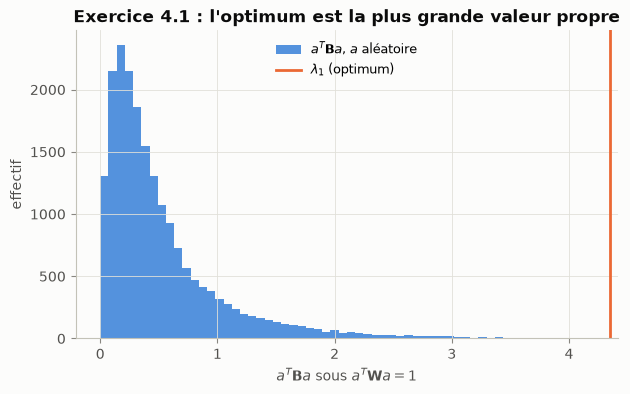

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(vals, bins=60, color=BLUE, alpha=0.8, label=r"$a^T\mathbf{B}a$, $a$ aléatoire")
ax.axvline(l1[-1], color=ORANGE, lw=2, label=r"$\lambda_1$ (optimum)")
ax.set_title("Exercice 4.1 : l'optimum est la plus grande valeur propre")
ax.set_xlabel(r"$a^T\mathbf{B}a$ sous $a^T\mathbf{W}a = 1$")
ax.set_ylabel("effectif")
ax.legend()
plt.show()

> **À retenir.** Le changement de variable $b = \mathbf{W}^{1/2}a$ (ou $b = \mathbf{L}^Ta$
> avec Cholesky) transforme la contrainte $a^T\mathbf{W}a = 1$ en $\|b\| = 1$ ; le
> problème devient la diagonalisation de la matrice symétrique
> $\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}$, et $a = \mathbf{W}^{-1/2}b$.

## Exercice 4.2 : LDA et moindres carrés à deux classes

**Énoncé.** On dispose de $x\in\mathbb{R}^p$ et d'une réponse à deux classes d'effectifs
$N_1, N_2$ ($N = N_1+N_2$), la cible étant codée $-N/N_1$ pour la classe 1 et $N/N_2$ pour la
classe 2.

(a) Montrer que la LDA classe en 2 si
$x^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) > \frac12(\hat\mu_2+\hat\mu_1)^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) - \log(N_2/N_1)$,
et en 1 sinon.

(b) On minimise $\sum_i(y_i-\beta_0-x_i^T\beta)^2$ (éq. (4.55)). Montrer que la solution
vérifie $\big[(N-2)\hat\Sigma + N\hat\Sigma_B\big]\beta = N(\hat\mu_2-\hat\mu_1)$ (éq. (4.56)),
où $\hat\Sigma_B = \frac{N_1N_2}{N^2}(\hat\mu_2-\hat\mu_1)(\hat\mu_2-\hat\mu_1)^T$.

(c) En déduire que $\hat\Sigma_B\beta$ est colinéaire à $\hat\mu_2-\hat\mu_1$, donc que
$\hat\beta \propto \hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1)$ (éq. (4.57)) : le coefficient des
moindres carrés est celui de la LDA à un facteur près.

(d) Montrer que ce résultat vaut pour tout codage (distinct) des deux classes.

(e) Trouver $\hat\beta_0$ et la fonction $\hat f(x) = \hat\beta_0 + x^T\hat\beta$. Montrer que
la règle « classer en 2 si $\hat f(x) > 0$ » ne coïncide avec la LDA que si $N_1 = N_2$.

### Notations

$\hat\mu_k$ est la moyenne de la classe $k$, $\bar x = (N_1\hat\mu_1 + N_2\hat\mu_2)/N$ la
moyenne globale, $d = \hat\mu_2 - \hat\mu_1$, et
$\hat\Sigma = \frac{1}{N-2}\sum_{k=1}^2\sum_{g_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^T$ la
covariance intra-classe. On suppose $\hat\Sigma$ inversible.

### (a) La règle LDA

Avec $\hat\pi_k = N_k/N$, la LDA classe en 2 si $\delta_2(x) > \delta_1(x)$, où
$\delta_k(x) = x^T\hat\Sigma^{-1}\hat\mu_k - \frac12\hat\mu_k^T\hat\Sigma^{-1}\hat\mu_k + \log\hat\pi_k$.
La différence vaut
$$\delta_2(x)-\delta_1(x) = x^T\hat\Sigma^{-1}d - \tfrac12\big(\hat\mu_2^T\hat\Sigma^{-1}\hat\mu_2 - \hat\mu_1^T\hat\Sigma^{-1}\hat\mu_1\big) + \log\frac{N_2}{N_1}.$$
Comme $\hat\Sigma^{-1}$ est symétrique, $\hat\mu_1^T\hat\Sigma^{-1}\hat\mu_2 = \hat\mu_2^T\hat\Sigma^{-1}\hat\mu_1$
et donc $(\hat\mu_2+\hat\mu_1)^T\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1) = \hat\mu_2^T\hat\Sigma^{-1}\hat\mu_2 - \hat\mu_1^T\hat\Sigma^{-1}\hat\mu_1$
(les termes croisés se compensent). La condition $\delta_2 > \delta_1$ s'écrit donc
exactement comme annoncé. $\square$

### (b) Les équations normales

Annulons les dérivées partielles du critère (4.55).

- Par rapport à $\beta_0$ : $\sum_i(y_i-\beta_0-x_i^T\beta) = 0$, d'où
  $\beta_0 = \bar y - \bar x^T\beta$. Or $\sum_iy_i = N_1\cdot(-N/N_1) + N_2\cdot N/N_2 = 0$,
  donc $\bar y = 0$ et $\boxed{\beta_0 = -\bar x^T\beta}$.
- Par rapport à $\beta$ : $\sum_ix_i(y_i-\beta_0-x_i^T\beta) = 0$. En remplaçant $\beta_0$ :
  $\sum_ix_i\big(y_i - (x_i-\bar x)^T\beta\big) = 0$.

Dans cette dernière somme, on peut remplacer $x_i$ par $x_i - \bar x$ devant la
parenthèse, car $\sum_i\bar x\big(y_i-(x_i-\bar x)^T\beta\big) = \bar x\big(\sum_iy_i - (\sum_i(x_i-\bar x))^T\beta\big) = 0$.
On obtient
$$\underbrace{\sum_i(x_i-\bar x)(x_i-\bar x)^T}_{\mathbf{T}}\ \beta = \sum_i(x_i - \bar x)\,y_i = \sum_ix_iy_i.$$

**Le second membre.** Les $y_i$ étant constants par classe,
$$\sum_ix_iy_i = -\frac{N}{N_1}\sum_{g_i=1}x_i + \frac{N}{N_2}\sum_{g_i=2}x_i = -\frac{N}{N_1}N_1\hat\mu_1 + \frac{N}{N_2}N_2\hat\mu_2 = N(\hat\mu_2-\hat\mu_1).$$

**La matrice $\mathbf{T}$ (dispersion totale).** On écrit $x_i - \bar x = (x_i - \hat\mu_k) + (\hat\mu_k - \bar x)$
pour $g_i = k$ et on développe. Les termes croisés sont nuls car
$\sum_{g_i=k}(x_i-\hat\mu_k) = 0$ (définition de $\hat\mu_k$). Il reste
$$\mathbf{T} = \underbrace{\sum_k\sum_{g_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^T}_{=(N-2)\hat\Sigma} + \sum_kN_k(\hat\mu_k-\bar x)(\hat\mu_k-\bar x)^T.$$
Or $\hat\mu_1 - \bar x = \frac{N_2}{N}(\hat\mu_1-\hat\mu_2) = -\frac{N_2}{N}d$ et
$\hat\mu_2-\bar x = \frac{N_1}{N}d$, donc le second terme vaut
$$N_1\frac{N_2^2}{N^2}dd^T + N_2\frac{N_1^2}{N^2}dd^T = \frac{N_1N_2(N_1+N_2)}{N^2}dd^T = N\cdot\frac{N_1N_2}{N^2}dd^T = N\hat\Sigma_B.$$
D'où $\big[(N-2)\hat\Sigma + N\hat\Sigma_B\big]\beta = N(\hat\mu_2-\hat\mu_1)$. $\square$

### (c) Colinéarité avec la direction LDA

$\hat\Sigma_B\beta = \frac{N_1N_2}{N^2}d\,(d^T\beta)$ et $d^T\beta$ est un **scalaire** :
$\hat\Sigma_B\beta$ est donc colinéaire à $d$. L'équation (4.56) donne alors
$$(N-2)\hat\Sigma\beta = Nd - N\hat\Sigma_B\beta = \Big(N - \frac{N_1N_2}{N}d^T\beta\Big)d,$$
d'où $\hat\beta \propto \hat\Sigma^{-1}d = \hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1)$.

On peut même calculer le facteur : en cherchant $\hat\beta = \kappa\hat\Sigma^{-1}d$ et en
notant $\Delta^2 = d^T\hat\Sigma^{-1}d$ (carré de la distance de Mahalanobis entre les
centroïdes), (4.56) devient $\kappa\big[(N-2) + \frac{N_1N_2}{N}\Delta^2\big]d = Nd$, soit
$$\kappa = \frac{N}{N-2+\frac{N_1N_2}{N}\Delta^2} > 0.$$

### (d) Tout codage convient

Soit un codage quelconque $a$ (classe 1), $b$ (classe 2), avec $a\neq b$. Il existe une
unique application affine $t\mapsto\alpha t+\gamma$ envoyant $-N/N_1$ sur $a$ et $N/N_2$ sur
$b$, et $\alpha = \frac{b-a}{N/N_2 + N/N_1} \ne 0$. Les nouvelles réponses sont donc
$y_i' = \alpha y_i + \gamma$.

Or les moindres carrés **avec constante** sont équivariants par transformation affine de
la réponse : si $(\hat\beta_0,\hat\beta)$ minimise $\sum(y_i-\beta_0-x_i^T\beta)^2$, alors
$(\alpha\hat\beta_0+\gamma, \alpha\hat\beta)$ minimise $\sum(y_i'-\beta_0-x_i^T\beta)^2$
(car $y_i' - (\alpha\beta_0+\gamma) - x_i^T(\alpha\beta) = \alpha(y_i - \beta_0 - x_i^T\beta)$,
et la correspondance est bijective). Donc $\hat\beta' = \alpha\hat\beta \propto \hat\Sigma^{-1}d$. $\square$

### (e) Le seuil diffère si $N_1\neq N_2$

D'après (b), $\hat\beta_0 = -\bar x^T\hat\beta$, donc
$$\hat f(x) = (x-\bar x)^T\hat\beta = \kappa\,(x-\bar x)^T\hat\Sigma^{-1}d.$$
Comme $\kappa > 0$, la règle $\hat f(x) > 0$ s'écrit $x^T\hat\Sigma^{-1}d > \bar x^T\hat\Sigma^{-1}d$.

Comparons ce seuil à celui de la LDA, $\frac12(\hat\mu_1+\hat\mu_2)^T\hat\Sigma^{-1}d - \log(N_2/N_1)$.
Comme $\bar x - \frac12(\hat\mu_1+\hat\mu_2) = \frac{N_1\hat\mu_1+N_2\hat\mu_2}{N} - \frac{\hat\mu_1+\hat\mu_2}{2} = \frac{N_2-N_1}{2N}d$,
$$\text{seuil}_{\text{MC}} - \text{seuil}_{\text{LDA}} = \frac{N_2-N_1}{2N}\Delta^2 + \log\frac{N_2}{N_1}.$$

- Si $N_1 = N_2$, les deux termes sont nuls : les règles **coïncident**.
- Si $N_2 > N_1$, les deux termes sont **strictement positifs** (avec $\Delta > 0$, ce qui
  est le cas dès que $\hat\mu_1\neq\hat\mu_2$) ; si $N_2 < N_1$, ils sont tous deux
  strictement négatifs. La différence n'est donc jamais nulle : les règles diffèrent.

Remarquons le sens de l'écart : quand $N_2 > N_1$, le seuil des moindres carrés est
**plus haut**, donc il classe *moins* en 2 que la LDA, alors que la classe 2 est la plus
fréquente. $\square$

### Vérification numérique

Deux classes gaussiennes de même covariance, effectifs $N_1 = 40$ et $N_2 = 160$.

In [5]:
rng = np.random.RandomState(0)
S2 = np.array([[1.0, 0.6], [0.6, 1.5]])
L2 = np.linalg.cholesky(S2)
N1, N2 = 40, 160
X2 = np.vstack([rng.randn(N1, 2) @ L2.T + [0, 0], rng.randn(N2, 2) @ L2.T + [1.5, 1.0]])
g2 = np.r_[np.ones(N1), 2 * np.ones(N2)]
N = N1 + N2
y2 = np.where(g2 == 1, -N / N1, N / N2)

lda2 = c4.lda_fit(X2, g2)
mu1, mu2 = lda2["means"]
Sig = lda2["cov"]
d = mu2 - mu1
Xa2 = np.column_stack([np.ones(N), X2])
b_ls = np.linalg.lstsq(Xa2, y2, rcond=None)[0]
Delta2 = d @ np.linalg.solve(Sig, d)
kappa = N / (N - 2 + N1 * N2 / N * Delta2)
print("beta (moindres carrés)       :", np.round(b_ls[1:], 6))
print("kappa * Sigma^-1 (mu2 - mu1) :", np.round(kappa * np.linalg.solve(Sig, d), 6))
print("beta0 = -xbar^T beta ?       :", np.isclose(b_ls[0], -X2.mean(axis=0) @ b_ls[1:]))

beta (moindres carrés)       : [0.9774   0.174188]
kappa * Sigma^-1 (mu2 - mu1) : [0.9774   0.174188]
beta0 = -xbar^T beta ?       : True


In [6]:
SigB = N1 * N2 / N ** 2 * np.outer(d, d)
print("Équation (4.56) vérifiée :", np.allclose(((N - 2) * Sig + N * SigB) @ b_ls[1:], N * d))
for (a_, b_) in [(0, 1), (1, -1), (-3, 7)]:
    y_alt = np.where(g2 == 1, a_, b_)
    b_alt = np.linalg.lstsq(Xa2, y_alt, rcond=None)[0]
    cos = b_alt[1:] @ b_ls[1:] / (np.linalg.norm(b_alt[1:]) * np.linalg.norm(b_ls[1:]))
    print("codage (%2d, %2d) : cos(angle avec beta) = %+.6f" % (a_, b_, cos))

Équation (4.56) vérifiée : True
codage ( 0,  1) : cos(angle avec beta) = +1.000000
codage ( 1, -1) : cos(angle avec beta) = -1.000000
codage (-3,  7) : cos(angle avec beta) = +1.000000


Les directions coïncident (cosinus $\pm1$, le signe dépendant de l'ordre du codage).
Comparons maintenant les **règles** : même direction, seuils différents.

In [7]:
pred_lda = c4.lda_predict(lda2, X2)
pred_ls = np.where(Xa2 @ b_ls > 0, 2, 1)
print("Points classés différemment :", np.sum(pred_lda != pred_ls))
print("Erreur d'apprentissage  LDA : %.3f   moindres carrés : %.3f" % (
    c4.error_rate(g2, pred_lda), c4.error_rate(g2, pred_ls)))
ecart_theo = (N2 - N1) / (2 * N) * Delta2 + np.log(N2 / N1)
seuil_ls = X2.mean(axis=0) @ np.linalg.solve(Sig, d)
seuil_lda = 0.5 * (mu1 + mu2) @ np.linalg.solve(Sig, d) - np.log(N2 / N1)
print("Écart des seuils : %.4f (formule : %.4f)" % (seuil_ls - seuil_lda, ecart_theo))

Points classés différemment : 79
Erreur d'apprentissage  LDA : 0.130   moindres carrés : 0.375
Écart des seuils : 2.0093 (formule : 2.0093)


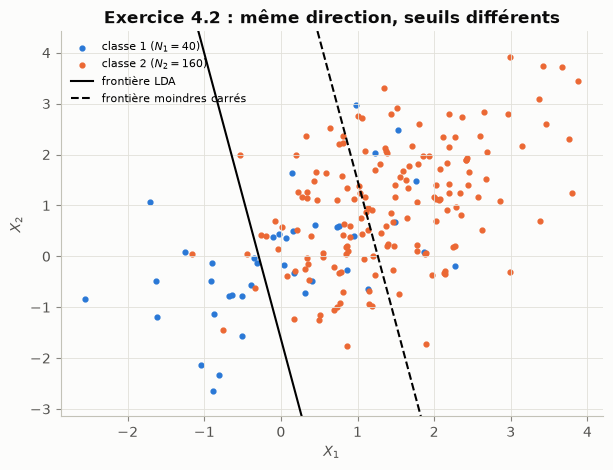

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(*X2[g2 == 1].T, s=12, color=BLUE, label="classe 1 ($N_1=40$)")
ax.scatter(*X2[g2 == 2].T, s=12, color=ORANGE, label="classe 2 ($N_2=160$)")
xs = np.array([X2[:, 0].min(), X2[:, 0].max()])
w_dir = np.linalg.solve(Sig, d)
for seuil, nom, ls in [(seuil_lda, "LDA", "-"), (seuil_ls, "moindres carrés", "--")]:
    ax.plot(xs, (seuil - w_dir[0] * xs) / w_dir[1], color="k", ls=ls, lw=1.5, label="frontière " + nom)
ax.set_ylim(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5)
ax.set_title("Exercice 4.2 : même direction, seuils différents")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.legend(fontsize=8)
plt.show()

Les deux frontières sont **parallèles** ; celle des moindres carrés est décalée vers la
grande classe (orange), comme prévu par le signe de l'écart. Avec des effectifs aussi
déséquilibrés (1 contre 4) et des classes peu séparées, le décalage est considérable : la
règle des moindres carrés fait ici bien pire que la LDA (et même pire que la règle triviale
« toujours classe 2 », d'erreur 0,20).

> **À retenir.** À deux classes, la régression d'une réponse codée par deux valeurs
> quelconques donne la **direction** de la LDA, $\hat\Sigma^{-1}(\hat\mu_2-\hat\mu_1)$ ;
> seul le **seuil** diffère lorsque les effectifs sont inégaux. En pratique, on peut
> garder la direction et choisir le seuil qui minimise l'erreur d'apprentissage.

## Exercice 4.3 : LDA sur les réponses ajustées

**Énoncé.** On transforme les prédicteurs $X$ en $\hat Y$ par régression linéaire :
$\hat{\mathbf{Y}} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{Y} = \mathbf{X}\hat{\mathbf{B}}$,
où $\mathbf{Y}$ est la matrice indicatrice ; pour une entrée $x$, $\hat y = \hat{\mathbf{B}}^Tx\in\mathbb{R}^K$.
Montrer que la LDA effectuée sur $\hat Y$ est identique à la LDA dans l'espace d'origine.

### Mise en place

$\mathbf{X}$ contient une colonne de 1, de sorte que $\hat y = b_0 + \mathbf{B}_1^Tx$ où
$\mathbf{B}_1$ ($p\times K$) regroupe les pentes. Classiquement (régression avec constante),
$$\mathbf{B}_1 = \mathbf{T}^{-1}\mathbf{X}_c^T\mathbf{Y}, \qquad \mathbf{T} = \mathbf{X}_c^T\mathbf{X}_c,$$
où $\mathbf{X}_c$ est la matrice des prédicteurs **centrés** (lignes $x_i-\bar x$) et
$\mathbf{T}$ la dispersion totale. La colonne $k$ de $\mathbf{X}_c^T\mathbf{Y}$ vaut
$\sum_{g_i=k}(x_i-\bar x) = N_k(\hat\mu_k-\bar x)$. Notons $\mathcal{S} = \operatorname{vect}\{\hat\mu_k-\bar x,\ k=1..K\}$ ;
alors $\operatorname{Im}(\mathbf{B}_1) = \mathbf{T}^{-1}\mathcal{S}$.

**Les paramètres de la LDA dans l'espace $\hat y$.** Posons $\mathbf{A} = \mathbf{B}_1^T$
($K\times p$). Puisque $\hat y_i = b_0 + \mathbf{A}x_i$ :

- moyenne de la classe $k$ : $m_k = b_0 + \mathbf{A}\hat\mu_k$ ;
- écarts intra-classe : $\hat y_i - m_k = \mathbf{A}(x_i - \hat\mu_k)$, d'où la covariance
  intra-classe $\mathbf{G} = \mathbf{A}\hat\Sigma\mathbf{A}^T$ ;
- mêmes proportions $\hat\pi_k$.

**Difficulté :** $\mathbf{G}$ est **singulière**. En effet, les composantes de $\hat y$
somment à 1 (cours 1), donc $\mathbf{1}_K^T\mathbf{A} = 0$ : $\hat y$ vit dans un
sous-espace affine de dimension $\le K-1$.

### Outil : pseudo-inverse

Pour une matrice symétrique semi-définie positive $\mathbf{G} = \sum_{j=1}^r\gamma_ju_ju_j^T$
($\gamma_j > 0$, $u_j$ orthonormés, $r$ = rang), la **pseudo-inverse** (de Moore-Penrose) est
$\mathbf{G}^+ = \sum_{j=1}^r\gamma_j^{-1}u_ju_j^T$ : elle inverse $\mathbf{G}$ sur son image
et vaut 0 sur l'orthogonal. Toutes les données $\hat y_i - m_k$ vivent dans
$\operatorname{Im}(\mathbf{A}) = \operatorname{Im}(\mathbf{G})$ : la LDA dans l'espace $\hat y$
se définit naturellement avec $\mathbf{G}^+$ à la place de $\mathbf{G}^{-1}$ (c'est la LDA
usuelle dans ce sous-espace ; de manière équivalente, on peut supprimer une coordonnée
redondante de $\hat y$).

**Fait (projection).** Si $\mathbf{C}$ est une matrice quelconque, $\mathbf{C}(\mathbf{C}^T\mathbf{C})^+\mathbf{C}^T$
est la projection orthogonale sur $\operatorname{Im}(\mathbf{C})$.

*Preuve.* Écrivons la décomposition en valeurs singulières réduite
$\mathbf{C} = \mathbf{U}\mathbf{D}\mathbf{V}^T$ ($\mathbf{D}$ diagonale $r\times r$ inversible,
$\mathbf{U}^T\mathbf{U} = \mathbf{V}^T\mathbf{V} = \mathbf{I}_r$). Alors
$\mathbf{C}^T\mathbf{C} = \mathbf{V}\mathbf{D}^2\mathbf{V}^T$, donc $(\mathbf{C}^T\mathbf{C})^+ = \mathbf{V}\mathbf{D}^{-2}\mathbf{V}^T$
et $\mathbf{C}(\mathbf{C}^T\mathbf{C})^+\mathbf{C}^T = \mathbf{U}\mathbf{D}\mathbf{V}^T\mathbf{V}\mathbf{D}^{-2}\mathbf{V}^T\mathbf{V}\mathbf{D}\mathbf{U}^T = \mathbf{U}\mathbf{U}^T$,
projecteur orthogonal sur $\operatorname{Im}(\mathbf{U}) = \operatorname{Im}(\mathbf{C})$. $\square$

### Lemme clé : $\hat\Sigma^{-1}\mathcal{S} = \mathbf{T}^{-1}\mathcal{S}$

Comme à l'exercice 4.2, $\mathbf{T} = (N-K)\hat\Sigma + \sum_kN_k(\hat\mu_k-\bar x)(\hat\mu_k-\bar x)^T$.
Pour $v\in\mathcal{S}$ :
$$\mathbf{T}\hat\Sigma^{-1}v = (N-K)v + \sum_kN_k(\hat\mu_k-\bar x)\big[(\hat\mu_k-\bar x)^T\hat\Sigma^{-1}v\big]\in\mathcal{S},$$
car c'est une combinaison linéaire de $v$ et des $\hat\mu_k-\bar x$. Donc
$\mathbf{T}(\hat\Sigma^{-1}\mathcal{S})\subset\mathcal{S}$. Comme $\mathbf{T}$ et $\hat\Sigma^{-1}$
sont inversibles, $\dim\mathbf{T}(\hat\Sigma^{-1}\mathcal{S}) = \dim\mathcal{S}$, d'où l'égalité
$\mathbf{T}(\hat\Sigma^{-1}\mathcal{S}) = \mathcal{S}$, c'est-à-dire $\hat\Sigma^{-1}\mathcal{S} = \mathbf{T}^{-1}\mathcal{S}$. $\square$

### Démonstration

Pour deux classes $k,\ell$, la LDA dans l'espace d'origine compare (cours 1, éq. (4.9))
$$\delta_k(x)-\delta_\ell(x) = \big(x - \tfrac{\hat\mu_k+\hat\mu_\ell}{2}\big)^T\hat\Sigma^{-1}(\hat\mu_k-\hat\mu_\ell) + \log\frac{\hat\pi_k}{\hat\pi_\ell}.$$
Dans l'espace $\hat y$, de même avec $\mathbf{G}^+$ :
$$\delta^{\hat y}_k-\delta^{\hat y}_\ell = \big(\hat y - \tfrac{m_k+m_\ell}{2}\big)^T\mathbf{G}^+(m_k-m_\ell) + \log\frac{\hat\pi_k}{\hat\pi_\ell}
= \big(x - \tfrac{\hat\mu_k+\hat\mu_\ell}{2}\big)^T\,\mathbf{A}^T\mathbf{G}^+\mathbf{A}\,(\hat\mu_k-\hat\mu_\ell) + \log\frac{\hat\pi_k}{\hat\pi_\ell},$$
car $\hat y - \frac{m_k+m_\ell}{2} = \mathbf{A}\big(x - \frac{\hat\mu_k+\hat\mu_\ell}{2}\big)$ ($b_0$ se simplifie) et $m_k - m_\ell = \mathbf{A}(\hat\mu_k-\hat\mu_\ell)$.

Posons $\mathbf{C} = \hat\Sigma^{1/2}\mathbf{A}^T$. Alors $\mathbf{G} = \mathbf{C}^T\mathbf{C}$ et
$$\mathbf{A}^T\mathbf{G}^+\mathbf{A} = \hat\Sigma^{-1/2}\,\mathbf{C}(\mathbf{C}^T\mathbf{C})^+\mathbf{C}^T\,\hat\Sigma^{-1/2} = \hat\Sigma^{-1/2}\mathbf{P}\hat\Sigma^{-1/2},$$
où $\mathbf{P}$ est la projection orthogonale sur $\operatorname{Im}(\mathbf{C})$ (fait
ci-dessus). Or, par le lemme,
$\operatorname{Im}(\mathbf{C}) = \hat\Sigma^{1/2}\operatorname{Im}(\mathbf{B}_1) = \hat\Sigma^{1/2}\mathbf{T}^{-1}\mathcal{S} = \hat\Sigma^{1/2}\hat\Sigma^{-1}\mathcal{S} = \hat\Sigma^{-1/2}\mathcal{S}$.

Enfin $\hat\mu_k-\hat\mu_\ell = (\hat\mu_k-\bar x)-(\hat\mu_\ell-\bar x)\in\mathcal{S}$, donc
$\hat\Sigma^{-1/2}(\hat\mu_k-\hat\mu_\ell)\in\operatorname{Im}(\mathbf{C})$ est **laissé fixe**
par $\mathbf{P}$. Ainsi
$$\mathbf{A}^T\mathbf{G}^+\mathbf{A}(\hat\mu_k-\hat\mu_\ell) = \hat\Sigma^{-1/2}\hat\Sigma^{-1/2}(\hat\mu_k-\hat\mu_\ell) = \hat\Sigma^{-1}(\hat\mu_k-\hat\mu_\ell),$$
et $\delta^{\hat y}_k-\delta^{\hat y}_\ell = \delta_k-\delta_\ell$ pour tous $k,\ell$ et tout $x$.
Les deux LDA prennent donc **exactement les mêmes décisions**. $\square$

> **Intuition.** Le lemme dit que l'information utile à la LDA (les directions
> $\hat\Sigma^{-1}(\hat\mu_k-\hat\mu_\ell)$) est entièrement contenue dans les $K-1$
> combinaisons linéaires $\hat y$ : la régression n'a rien perdu de ce dont la LDA a besoin,
> et la LDA « recolle » ensuite la bonne métrique.

### Vérification numérique sur les voyelles

On calcule $\hat{\mathbf{Y}}$, puis la LDA sur $\hat Y$ de deux façons : avec la
pseudo-inverse, et en supprimant la dernière coordonnée (redondante).

In [9]:
Xtr, ytr = datasets.load_vowel("train")
Xte, yte = datasets.load_vowel("test")
reg = c4.indicator_regression_fit(Xtr, ytr)
_, Yhat_tr = c4.indicator_regression_predict(reg, Xtr, return_fitted=True)
_, Yhat_te = c4.indicator_regression_predict(reg, Xte, return_fitted=True)

lda_y = c4.lda_fit(Yhat_tr, ytr)                      # moyennes et covariance (singulière)
print("Valeurs propres de G (les plus petites) :", np.round(np.linalg.eigvalsh(lda_y["cov"])[:3], 10))
Gp = np.linalg.pinv(lda_y["cov"], hermitian=True)
A_ = Gp @ lda_y["means"].T
D_pinv = Yhat_te @ A_ - 0.5 * np.sum(lda_y["means"].T * A_, axis=0) + np.log(lda_y["priors"])
pred_pinv = lda_y["classes"][np.argmax(D_pinv, axis=1)]

lda_drop = c4.lda_fit(Yhat_tr[:, :-1], ytr)
pred_drop = c4.lda_predict(lda_drop, Yhat_te[:, :-1])
pred_orig = c4.lda_predict(c4.lda_fit(Xtr, ytr), Xte)
print("LDA(Ŷ, pseudo-inverse) = LDA(X) :", np.array_equal(pred_pinv, pred_orig))
print("LDA(Ŷ sans dernière colonne) = LDA(X) :", np.array_equal(pred_drop, pred_orig))
print("Erreur de test commune : %.3f" % c4.error_rate(yte, pred_orig))

Valeurs propres de G (les plus petites) : [0.00000e+00 5.65887e-05 9.16247e-05]
LDA(Ŷ, pseudo-inverse) = LDA(X) : True
LDA(Ŷ sans dernière colonne) = LDA(X) : True
Erreur de test commune : 0.556


Le résultat est particulièrement frappant si l'on se souvient que la **régression** elle-même
(argmax de $\hat y$) a une erreur de test de 0,67 sur ces données : la régression perd de
l'information *dans sa règle de décision* (masquage), pas dans les variables $\hat y$.

Vérifions aussi le cas $K - 1 < p$ (où $\hat Y$ réduit vraiment la dimension), sur 4 voyelles.

In [10]:
m4, m4te = ytr <= 4, yte <= 4
reg4 = c4.indicator_regression_fit(Xtr[m4], ytr[m4])
Y4 = c4.indicator_regression_predict(reg4, Xtr[m4], return_fitted=True)[1][:, :-1]
Y4te = c4.indicator_regression_predict(reg4, Xte[m4te], return_fitted=True)[1][:, :-1]
D1 = c4.lda_decision_function(c4.lda_fit(Y4, ytr[m4]), Y4te)
D2 = c4.lda_decision_function(c4.lda_fit(Xtr[m4], ytr[m4]), Xte[m4te])
print("Dimension de Ŷ utilisée :", Y4.shape[1], "au lieu de p =", Xtr.shape[1])
print("Différences delta_k - delta_1 identiques :", np.allclose(D1 - D1[:, :1], D2 - D2[:, :1]))

Dimension de Ŷ utilisée : 3 au lieu de p = 10
Différences delta_k - delta_1 identiques : True


> **À retenir.** La LDA sur les $K$ (en fait $K-1$) réponses ajustées $\hat y$ de la
> régression sur indicatrices est **identique** à la LDA sur $x$ : le sous-espace engendré
> par les coefficients de la régression contient toutes les directions discriminantes
> $\hat\Sigma^{-1}(\hat\mu_k-\hat\mu_\ell)$.

## Exercice 4.4 : Newton-Raphson pour la logistique multinomiale

**Énoncé.** On considère le modèle multilogit à $K$ classes (4.17). Soit $\beta$ le vecteur
de taille $(p+1)(K-1)$ regroupant tous les coefficients. Définir une version convenablement
agrandie du vecteur d'entrée $x$ adaptée à ce vecteur de coefficients. Établir
l'algorithme de Newton-Raphson pour maximiser la log-vraisemblance multinomiale, et décrire
comment l'implémenter.

### Vectorisation

Notons $x_i\in\mathbb{R}^{p+1}$ l'entrée complétée d'un 1 initial, $\beta_k\in\mathbb{R}^{p+1}$
(constante incluse) les coefficients de la classe $k<K$ et
$\beta = (\beta_1^T, \dots, \beta_{K-1}^T)^T$. Pour chaque $k<K$, on définit l'**entrée
agrandie** $\tilde x_{ik}\in\mathbb{R}^{(p+1)(K-1)}$ : elle vaut $x_i$ dans le $k$-ième bloc
et 0 ailleurs,
$$\tilde x_{ik} = e_k\otimes x_i = (0,\dots,0,\ x_i^T,\ 0,\dots,0)^T.$$
Ainsi $\beta_k^Tx_i = \beta^T\tilde x_{ik}$ : chaque log-rapport est une forme linéaire
en $\beta$.

### Log-vraisemblance

Avec $y_{ik} = 1$ si $g_i = k$ (et 0 sinon), $\eta_{ik} = \beta^T\tilde x_{ik}$ et
$p_{ik} = \Pr(G=k\mid x_i) = e^{\eta_{ik}}/(1+\sum_{l<K}e^{\eta_{il}})$ :
$$\ell(\beta) = \sum_{i=1}^N\Big[\sum_{k<K}y_{ik}\,\beta^T\tilde x_{ik} - \log\Big(1+\sum_{l<K}e^{\beta^T\tilde x_{il}}\Big)\Big].$$
(Pour $g_i = K$, $\log p_{iK} = -\log(1+\sum_le^{\eta_{il}})$ ; pour $g_i = k<K$, on ajoute $\eta_{ik}$.)

### Gradient

La dérivée de $\log(1+\sum_le^{\eta_{il}})$ par rapport à $\beta$ est, par dérivation composée,
$\sum_l\frac{e^{\eta_{il}}}{1+\sum_me^{\eta_{im}}}\tilde x_{il} = \sum_lp_{il}\tilde x_{il}$. Donc
$$\nabla\ell(\beta) = \sum_{i=1}^N\sum_{k<K}(y_{ik}-p_{ik})\,\tilde x_{ik}.$$
Bloc par bloc : le $k$-ième bloc vaut $\sum_i(y_{ik}-p_{ik})x_i = \mathbf{X}^T(\mathbf{y}_k-\mathbf{p}_k)$.

### Hessienne

On dérive $p_{il}$ : $\frac{\partial p_{il}}{\partial\beta} = p_{il}\big(\tilde x_{il} - \sum_mp_{im}\tilde x_{im}\big)$
(dérivée d'un quotient). Donc
$$\nabla^2\ell(\beta) = -\sum_{i=1}^N\Big[\sum_{k<K}p_{ik}\tilde x_{ik}\tilde x_{ik}^T - \Big(\sum_kp_{ik}\tilde x_{ik}\Big)\Big(\sum_kp_{ik}\tilde x_{ik}\Big)^T\Big].$$
Bloc par bloc, le bloc $(k,l)$ vaut
$$-\sum_ip_{ik}(\delta_{kl}-p_{il})\,x_ix_i^T = -\mathbf{X}^T\mathbf{W}_{kl}\mathbf{X},\qquad \mathbf{W}_{kl} = \operatorname{diag}\big(p_{ik}(\delta_{kl}-p_{il})\big)_i.$$

> **Concavité.** Le crochet est la matrice de covariance d'un vecteur aléatoire valant
> $\tilde x_{ik}$ avec probabilité $p_{ik}$ ($k<K$) et $0$ avec probabilité $p_{iK}$ : il
> est semi-défini positif. La hessienne est donc semi-définie négative et $\ell$ concave,
> comme dans le cas binaire.

### L'algorithme

Newton-Raphson : $\beta^{\text{new}} = \beta^{\text{old}} + \big(-\nabla^2\ell\big)^{-1}\nabla\ell$.
En notant $\tilde{\mathbf{X}} = \mathbf{I}_{K-1}\otimes\mathbf{X}$ (matrice bloc-diagonale
$N(K-1)\times(p+1)(K-1)$), $\tilde{\mathbf{y}}$, $\tilde{\mathbf{p}}$ les vecteurs empilés
et $\tilde{\mathbf{W}}$ la matrice $N(K-1)\times N(K-1)$ formée des blocs $\mathbf{W}_{kl}$,
on a $\nabla\ell = \tilde{\mathbf{X}}^T(\tilde{\mathbf{y}}-\tilde{\mathbf{p}})$,
$-\nabla^2\ell = \tilde{\mathbf{X}}^T\tilde{\mathbf{W}}\tilde{\mathbf{X}}$ et, exactement comme
dans le cas binaire,
$$\beta^{\text{new}} = (\tilde{\mathbf{X}}^T\tilde{\mathbf{W}}\tilde{\mathbf{X}})^{-1}\tilde{\mathbf{X}}^T\tilde{\mathbf{W}}\tilde{\mathbf{z}},\qquad \tilde{\mathbf{z}} = \tilde{\mathbf{X}}\beta^{\text{old}} + \tilde{\mathbf{W}}^{-1}(\tilde{\mathbf{y}}-\tilde{\mathbf{p}}) :$$
c'est encore un IRLS, mais avec une matrice de poids **non diagonale**.

**Implémentation** (fonction `multilogit_newton` du module) :

1. initialiser $\beta = 0$ (toutes les probabilités valent $1/K$) ;
2. calculer les $p_{ik}$ de manière stable (soustraction du maximum avant l'exponentielle) ;
3. assembler le gradient par blocs $\mathbf{X}^T(\mathbf{y}_k-\mathbf{p}_k)$ et la hessienne par
   blocs $-\mathbf{X}^T\mathbf{W}_{kl}\mathbf{X}$ (inutile de former $\tilde{\mathbf{W}}$ : on
   ne stocke que des vecteurs de poids de taille $N$) ;
4. résoudre le système linéaire symétrique défini positif de taille $(p+1)(K-1)$ (Cholesky)
   plutôt que d'inverser ;
5. par sécurité, diviser le pas par 2 tant que la log-vraisemblance n'augmente pas ;
6. arrêter quand la variation relative de $\ell$ est négligeable.

Le coût par itération est $O\big(N(p+1)^2(K-1)^2 + (p+1)^3(K-1)^3\big)$.

### Vérifications numériques

D'abord, on contrôle sur un petit exemple que la construction « entrée agrandie »
(gradient et hessienne calculés avec les $\tilde x_{ik}$ explicites) coïncide avec la
formule par blocs.

In [11]:
rng = np.random.RandomState(0)
Nn, pp, KK = 30, 2, 3
Xs = rng.randn(Nn, pp)
gs = rng.randint(0, KK, Nn)
Xs1 = np.column_stack([np.ones(Nn), Xs])
q = pp + 1
beta = rng.randn(q * (KK - 1)) * 0.5

Xt = np.zeros((Nn, KK - 1, q * (KK - 1)))                 # entrées agrandies x~_ik
for k in range(KK - 1):
    Xt[:, k, k * q:(k + 1) * q] = Xs1
eta = Xt @ beta                                          # (N, K-1)
P = np.exp(eta) / (1 + np.exp(eta).sum(axis=1, keepdims=True))
Yk = (gs[:, None] == np.arange(KK - 1)).astype(float)
grad_tilde = np.einsum("ik,ikj->j", Yk - P, Xt)
m = np.einsum("ik,ikj->ij", P, Xt)
H_tilde = -(np.einsum("ik,ikj,ikl->jl", P, Xt, Xt) - m.T @ m)

grad_bloc = ((Yk - P).T @ Xs1).ravel()
H_bloc = np.block([[-(Xs1.T * (P[:, k] * ((k == l) - P[:, l]))) @ Xs1 for l in range(KK - 1)]
                   for k in range(KK - 1)])
print("Gradients égaux :", np.allclose(grad_tilde, grad_bloc))
print("Hessiennes égales :", np.allclose(H_tilde, H_bloc))
print("Hessienne semi-définie négative :", np.linalg.eigvalsh(H_bloc).max() <= 1e-10)

Gradients égaux : True
Hessiennes égales : True
Hessienne semi-définie négative : True


Le gradient se contrôle aussi par différences finies.

In [12]:
def loglik_multi(b):
    e = Xt @ b
    return np.sum(Yk * e) - np.sum(np.log1p(np.exp(e).sum(axis=1)))

h = 1e-6
grad_num = np.array([(loglik_multi(beta + h * e) - loglik_multi(beta - h * e)) / (2 * h)
                     for e in np.eye(len(beta))])
print("Écart max gradient analytique / numérique : %.2e" % np.max(np.abs(grad_num - grad_bloc)))

Écart max gradient analytique / numérique : 9.47e-09


Appliquons maintenant l'algorithme aux voyelles ($K = 11$, $p = 10$, soit 110 paramètres),
et comparons à scikit-learn (sans pénalité).

In [13]:
res = c4.multilogit_newton(Xtr, ytr)
print("Itérations :", res["n_iter"], " log-vraisemblance finale : %.4f" % res["loglik"])
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=np.inf, max_iter=20000, tol=1e-10).fit(Xtr, ytr)
print("Écart max des probabilités avec scikit-learn : %.1e" % np.max(np.abs(
    c4.multilogit_predict_proba(res, Xte) - sk.predict_proba(Xte))))
print("Erreurs  apprentissage : %.2f   test : %.2f   (tableau 4.1 : 0.22 / 0.51)" % (
    c4.error_rate(ytr, c4.multilogit_predict(res, Xtr)), c4.error_rate(yte, c4.multilogit_predict(res, Xte))))

Itérations : 10  log-vraisemblance finale : -338.4989


Écart max des probabilités avec scikit-learn : 7.3e-06
Erreurs  apprentissage : 0.22   test : 0.51   (tableau 4.1 : 0.22 / 0.51)


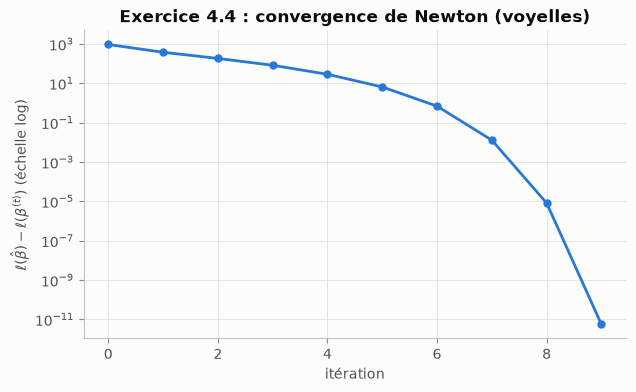

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(len(res["history"]) - 1), res["history"][-1] - res["history"][:-1], "o-", color=BLUE)
ax.set_title("Exercice 4.4 : convergence de Newton (voyelles)")
ax.set_xlabel("itération")
ax.set_ylabel(r"$\ell(\hat\beta) - \ell(\beta^{(t)})$ (échelle log)")
plt.show()

Une dizaine d'itérations suffit, avec la convergence quadratique caractéristique de
Newton (l'écart à l'optimum s'effondre dans les dernières itérations).

> **À retenir.** Avec l'entrée agrandie $\tilde x_{ik} = e_k\otimes x_i$, la logistique
> multinomiale a la même structure que la binaire : gradient
> $\sum_{i,k}(y_{ik}-p_{ik})\tilde x_{ik}$, hessienne $-\tilde{\mathbf{X}}^T\tilde{\mathbf{W}}\tilde{\mathbf{X}}$
> avec des poids $p_{ik}(\delta_{kl}-p_{il})$ formant des blocs **non diagonaux**, et Newton
> s'écrit comme un IRLS.

## Exercice 4.5 : Logistique sur des données séparables

**Énoncé.** Régression logistique à deux classes avec $x\in\mathbb{R}$. Caractériser les
estimateurs du maximum de vraisemblance de la pente et de la constante si les observations
des deux classes sont séparées par un point $x_0\in\mathbb{R}$. Généraliser (a) à
$x\in\mathbb{R}^p$ (voir la figure 4.16) et (b) à plus de deux classes.

### Cas $x\in\mathbb{R}$

Supposons, quitte à échanger les classes, $x_i < x_0$ lorsque $y_i = 0$ et $x_i > x_0$
lorsque $y_i = 1$. La log-vraisemblance est
$\ell(\beta_0,\beta_1) = \sum_{y_i=1}\log p_i + \sum_{y_i=0}\log(1-p_i)$ avec
$p_i = \sigma(\beta_0+\beta_1x_i)\in\,]0,1[$.

1. **Majoration.** Chaque terme est le logarithme d'un nombre de $]0,1[$, donc
   $\ell(\beta_0,\beta_1) < 0$ pour **tous** paramètres finis.
2. **Le supremum vaut 0.** Prenons $\beta_1 = c > 0$ et $\beta_0 = -cx_0$ :
   $\beta_0+\beta_1x_i = c(x_i-x_0)$, qui tend vers $+\infty$ si $y_i = 1$ et vers $-\infty$
   si $y_i = 0$ quand $c\to+\infty$. Donc chaque $p_i\to y_i$ et $\ell\to0$.

Conclusion : $\sup\ell = 0$ **n'est pas atteint** ; l'estimateur du maximum de vraisemblance
**n'existe pas** (on dit que les estimations « divergent »).

**Caractérisation des suites maximisantes.** Soit une suite $(\beta_0^{(m)},\beta_1^{(m)})$
telle que $\ell\to0$. Chaque terme (négatif) tend alors vers 0, donc
$\eta_i^{(m)} = \beta_0^{(m)}+\beta_1^{(m)}x_i \to +\infty$ si $y_i = 1$ et $\to-\infty$ si $y_i = 0$.
Soient $x_a = \max\{x_i : y_i = 0\}$ et $x_b = \min\{x_i : y_i = 1\}$ ($x_a < x_0 < x_b$). Alors
$\beta_1^{(m)}(x_b - x_a) = \eta_b^{(m)}-\eta_a^{(m)}\to+\infty$ : la **pente tend vers
$+\infty$**. De plus, pour $m$ grand, $\eta_a^{(m)}<0<\eta_b^{(m)}$, donc le point de
coupure $-\beta_0^{(m)}/\beta_1^{(m)}$ se trouve dans l'intervalle $]x_a, x_b[$ : la
constante tend vers $\mp\infty$ de sorte que la **frontière estimée sépare les classes**.
La probabilité ajustée devient une **marche** en ce point.